# Linear Regression with Python

### Objective: House Price Prediction

In [1]:
# Import the libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Import the data 

USAhousing = pd.read_csv("USA_housing.csv")
USAhousing

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386
...,...,...,...,...,...,...,...
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316


### Exploratory Data Analysis:

In [3]:
USAhousing.head()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06,"208 Michael Ferry Apt. 674\nLaurabury, NE 3701..."
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06,"188 Johnson Views Suite 079\nLake Kathleen, CA..."
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06,"9127 Elizabeth Stravenue\nDanieltown, WI 06482..."
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06,USS Barnett\nFPO AP 44820
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05,USNS Raymond\nFPO AE 09386


In [4]:
USAhousing.tail()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price,Address
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06,USNS Williams\nFPO AP 30153-7653
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06,"PSC 9258, Box 8489\nAPO AA 42991-3352"
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06,"4215 Tracy Garden Suite 076\nJoshualand, VA 01..."
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06,USS Wallace\nFPO AE 73316
4999,65510.581804,5.992305,6.792336,4.07,46501.283803,1.298950e+06,"37778 George Ridges Apt. 509\nEast Holly, NV 2..."


In [5]:
USAhousing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Avg. Area Income              5000 non-null   float64
 1   Avg. Area House Age           5000 non-null   float64
 2   Avg. Area Number of Rooms     5000 non-null   float64
 3   Avg. Area Number of Bedrooms  5000 non-null   float64
 4   Area Population               5000 non-null   float64
 5   Price                         5000 non-null   float64
 6   Address                       5000 non-null   object 
dtypes: float64(6), object(1)
memory usage: 273.6+ KB


In [6]:
USAhousing.isnull().sum() # to check null values

Avg. Area Income                0
Avg. Area House Age             0
Avg. Area Number of Rooms       0
Avg. Area Number of Bedrooms    0
Area Population                 0
Price                           0
Address                         0
dtype: int64

In [7]:
USAhousing.describe()

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5.000000e+03
mean,68583.108984,5.977222,6.987792,3.981330,36163.516039,1.232073e+06
std,10657.991214,0.991456,1.005833,1.234137,9925.650114,3.531176e+05
min,17796.631190,2.644304,3.236194,2.000000,172.610686,1.593866e+04
25%,61480.562388,5.322283,6.299250,3.140000,29403.928702,9.975771e+05
50%,68804.286404,5.970429,7.002902,4.050000,36199.406689,1.232669e+06
75%,75783.338666,6.650808,7.665871,4.490000,42861.290769,1.471210e+06
max,107701.748378,9.519088,10.759588,6.500000,69621.713378,2.469066e+06


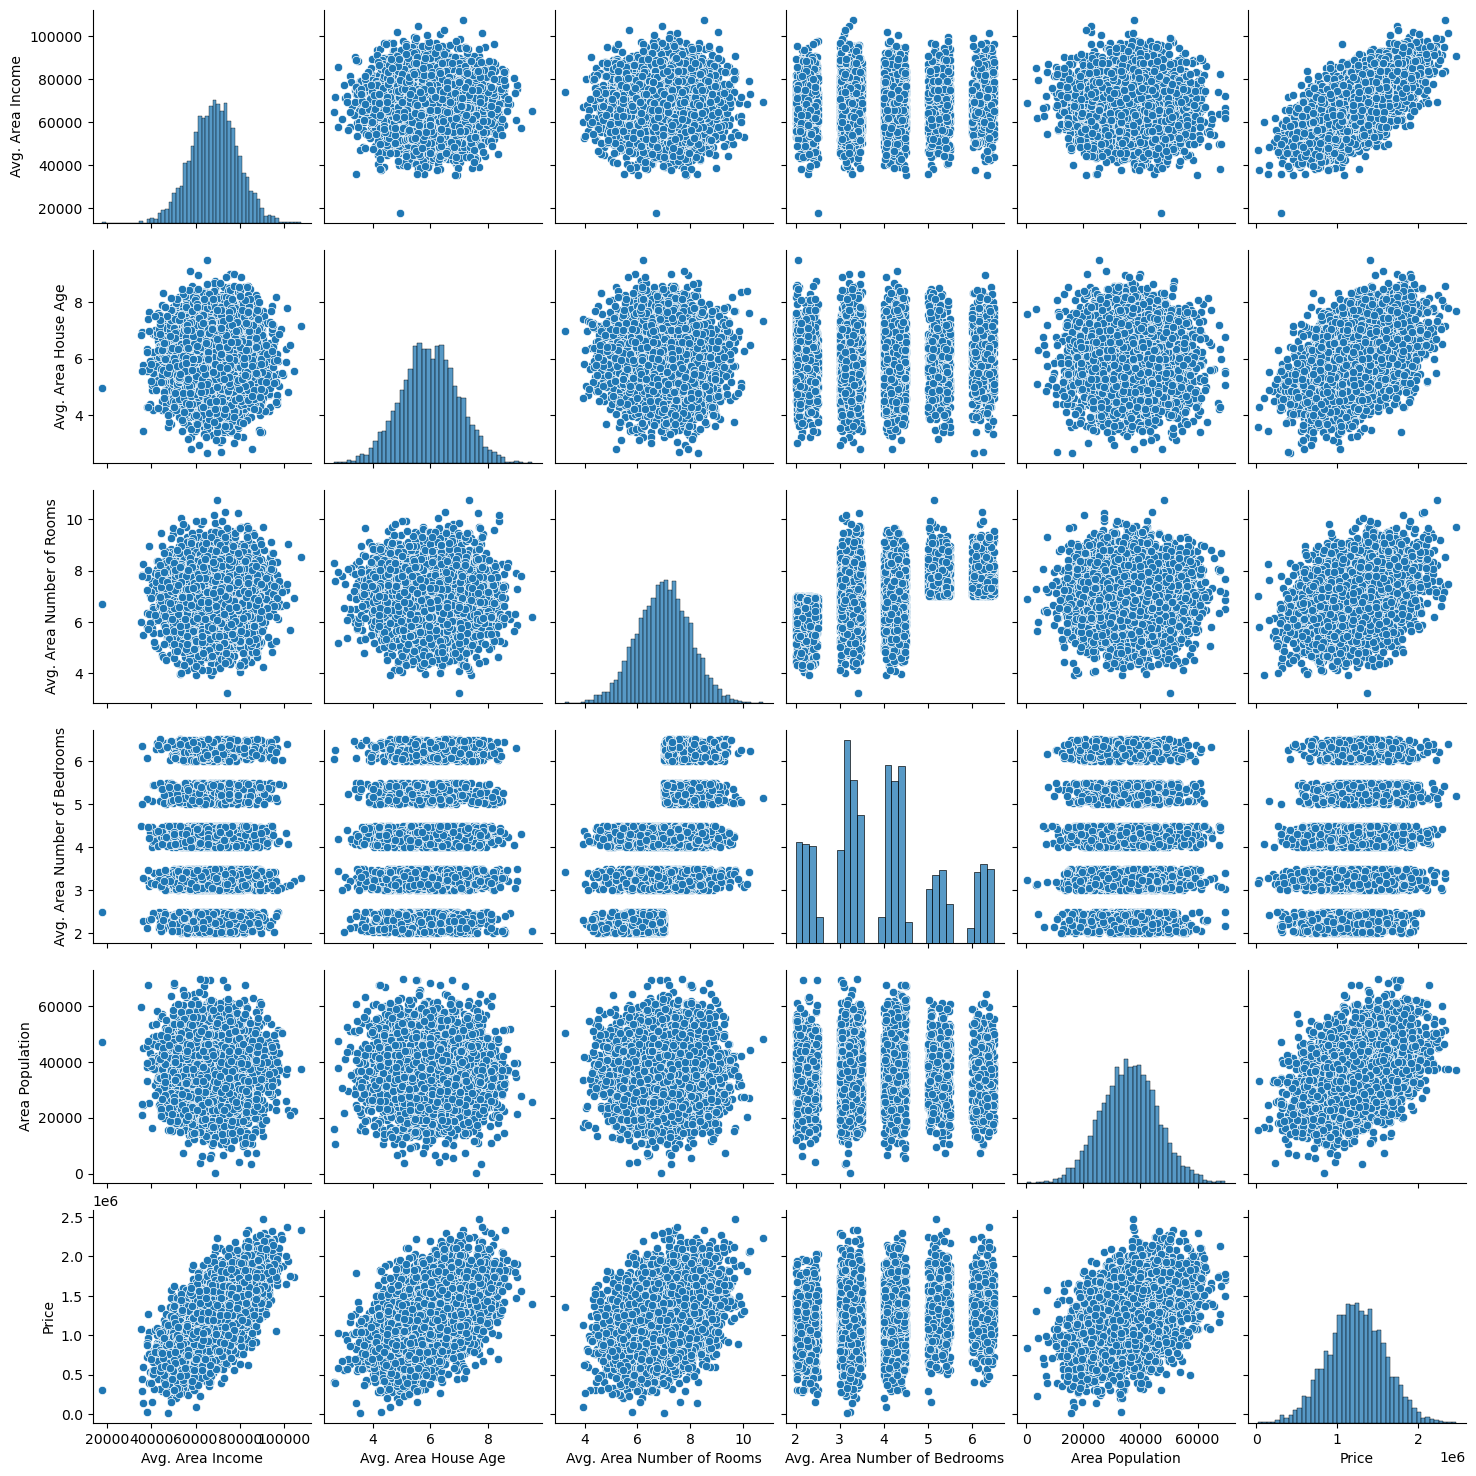

In [8]:
sns.pairplot(USAhousing)
plt.show()

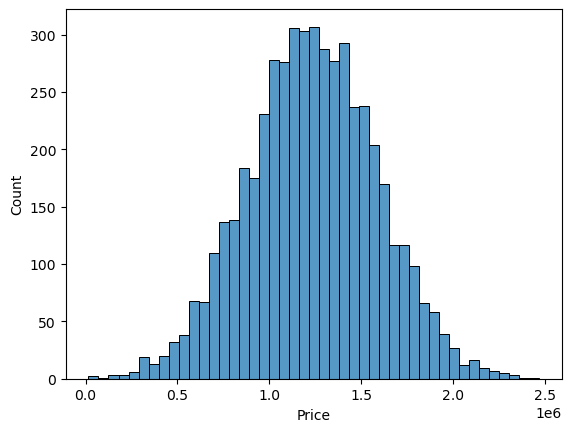

In [9]:
sns.histplot(USAhousing["Price"])
plt.show()

In [10]:
USAhousing.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [11]:
subset = USAhousing[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price']]
subset

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
0,79545.458574,5.682861,7.009188,4.09,23086.800503,1.059034e+06
1,79248.642455,6.002900,6.730821,3.09,40173.072174,1.505891e+06
2,61287.067179,5.865890,8.512727,5.13,36882.159400,1.058988e+06
3,63345.240046,7.188236,5.586729,3.26,34310.242831,1.260617e+06
4,59982.197226,5.040555,7.839388,4.23,26354.109472,6.309435e+05
...,...,...,...,...,...,...
4995,60567.944140,7.830362,6.137356,3.46,22837.361035,1.060194e+06
4996,78491.275435,6.999135,6.576763,4.02,25616.115489,1.482618e+06
4997,63390.686886,7.250591,4.805081,2.13,33266.145490,1.030730e+06
4998,68001.331235,5.534388,7.130144,5.44,42625.620156,1.198657e+06


In [13]:
corr = subset.corr()
corr

,Avg. Area Income,Avg. Area House Age,Avg. Area Number of Rooms,Avg. Area Number of Bedrooms,Area Population,Price
Avg. Area Income,1.000000,-0.002007,-0.011032,0.019788,-0.016234,0.639734
Avg. Area House Age,-0.002007,1.000000,-0.009428,0.006149,-0.018743,0.452543
Avg. Area Number of Rooms,-0.011032,-0.009428,1.000000,0.462695,0.002040,0.335664
Avg. Area Number of Bedrooms,0.019788,0.006149,0.462695,1.000000,-0.022168,0.171071
Area Population,-0.016234,-0.018743,0.002040,-0.022168,1.000000,0.408556
Price,0.639734,0.452543,0.335664,0.171071,0.408556,1.000000


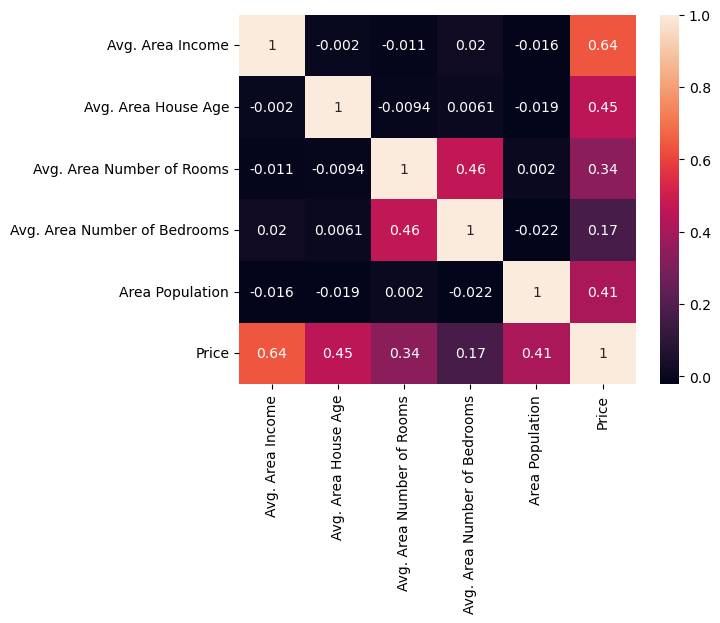

In [14]:
sns.heatmap(corr,annot=True)
plt.show()

### Insights:

1. Avg Area Income → Strong positive correlation with Price
2. Avg Area Number of Rooms → Strong positive correlation with Price
3. Area Population → Moderate positive correlation
4. Bedrooms → Weak relationship
5. House Age → Positive relationship

In [15]:
sns.set_style("whitegrid")

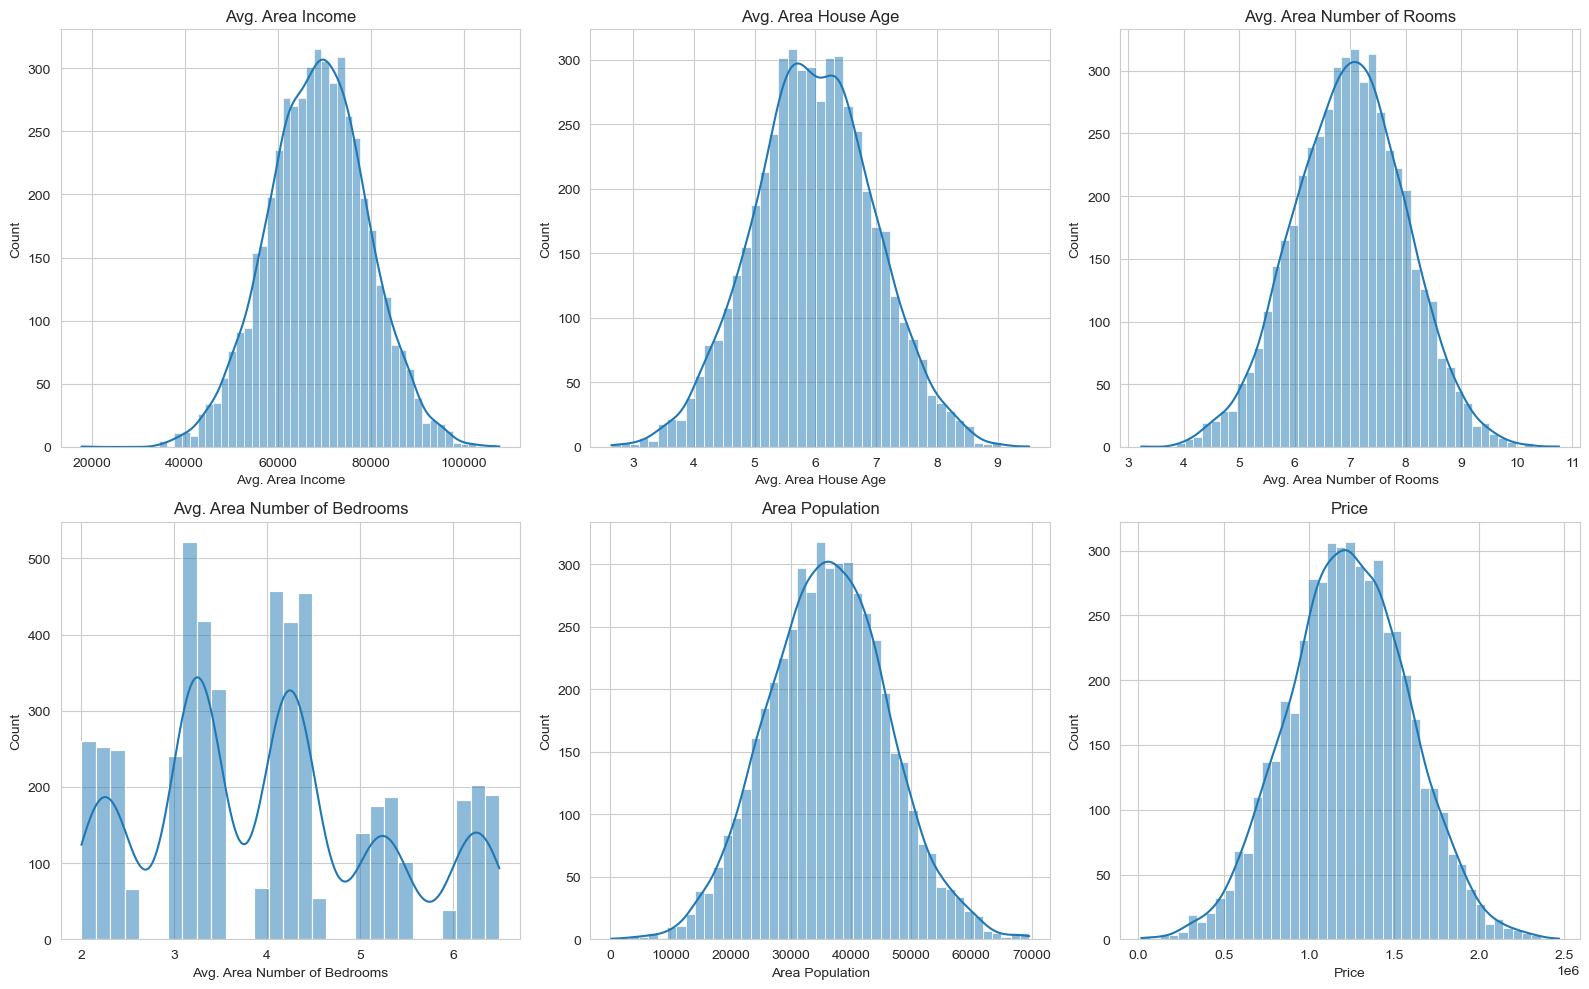

In [16]:
num_cols = USAhousing.select_dtypes(include='number').columns

fig, axes = plt.subplots(2, 3, figsize=(16,10))

for col, ax in zip(num_cols, axes.flatten()):
    sns.histplot(USAhousing[col], kde=True, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

Insights:

1. Check whether variables are normally distributed.
2. Detect skewness and outliers.
3. Price often appears approximately normal.

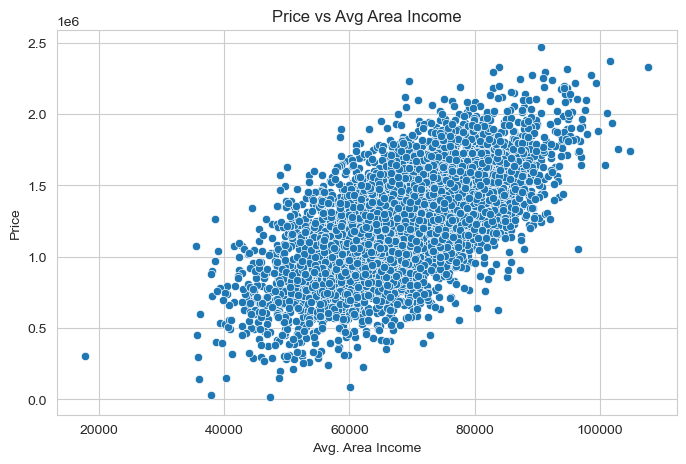

In [17]:
# Price Vs Income Graph:

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=USAhousing,
    x='Avg. Area Income',
    y='Price'
)

plt.title("Price vs Avg Area Income")
plt.show()

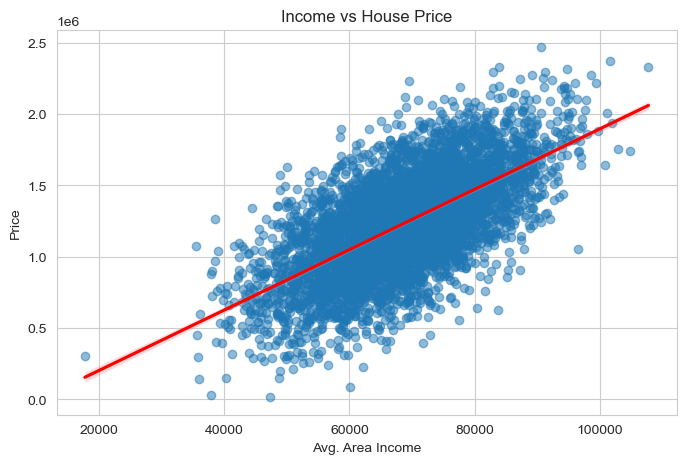

In [18]:
plt.figure(figsize=(8,5))

sns.regplot(
    data=USAhousing,
    x='Avg. Area Income',
    y='Price',
    scatter_kws={'alpha':0.5},
    line_kws={'color':'red'}
)

plt.title("Income vs House Price")
plt.show()

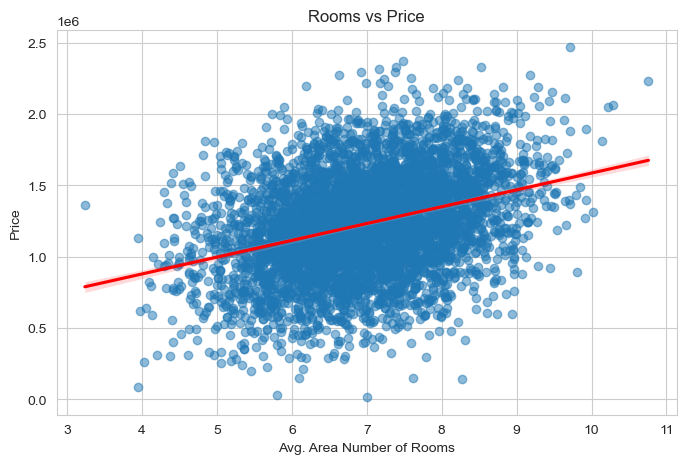

In [19]:
# Price vs No of rooms:

plt.figure(figsize=(8,5))

sns.regplot(
    data=USAhousing,
    x='Avg. Area Number of Rooms',
    y='Price',
    scatter_kws={'alpha':0.5},
    line_kws={'color':'red'}
)

plt.title("Rooms vs Price")
plt.show()

### Insight:

More rooms generally correspond to more expensive houses.

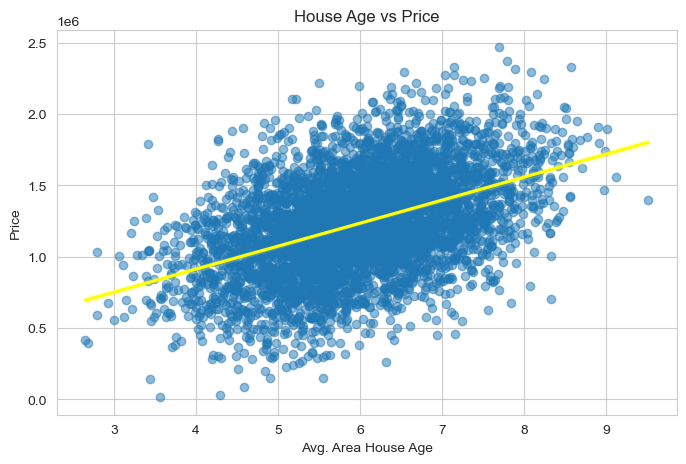

In [23]:
# Price Vs House Age:

plt.figure(figsize=(8,5))

sns.regplot(
    data=USAhousing,
    x='Avg. Area House Age',
    y='Price',
    scatter_kws={'alpha':0.5},
    line_kws={'color':'yellow'}
)

plt.title("House Age vs Price")
plt.show()

### Insight:

Older houses may belong to established, high-value neighborhoods

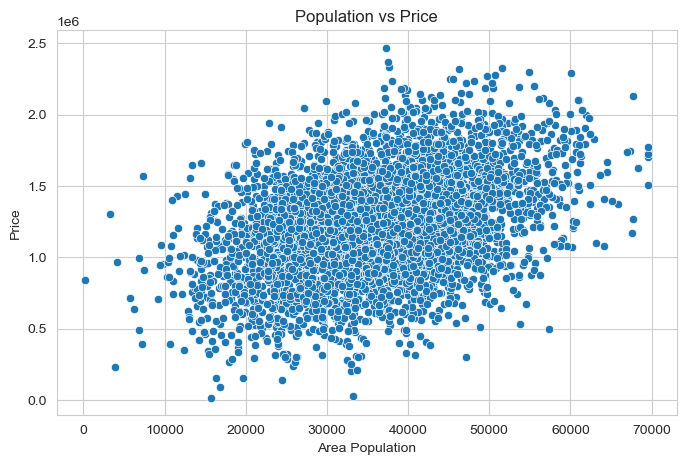

In [24]:
# Price Vs Population:

plt.figure(figsize=(8,5))

sns.scatterplot(
    data=USAhousing,
    x='Area Population',
    y='Price'
)

plt.title("Population vs Price")
plt.show()

#### Insight

Relationship exists but is generally weaker than income and rooms.

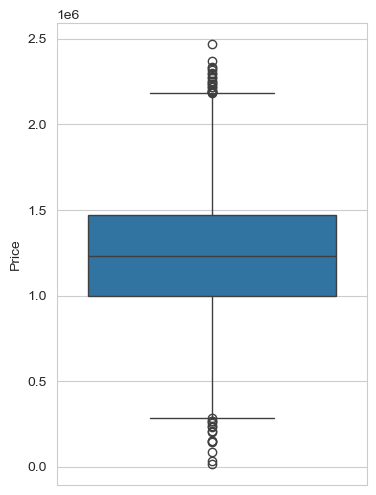

In [32]:
# Outlier detection:

plt.figure(figsize=(4,6))

sns.boxplot(data=USAhousing["Price"])

plt.xticks(rotation=45)
plt.show()

In [27]:
USAhousing.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

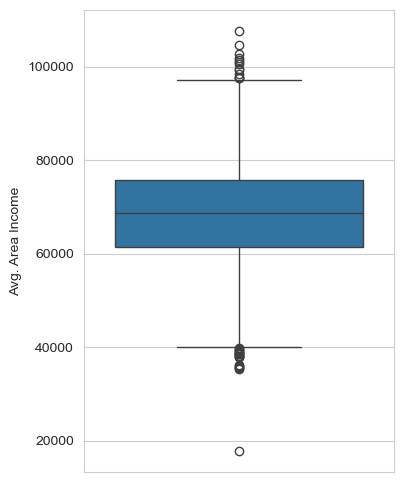

In [33]:
# Outlier detection:

plt.figure(figsize=(4,6))

sns.boxplot(data=USAhousing["Avg. Area Income"])

plt.xticks(rotation=45)
plt.show()

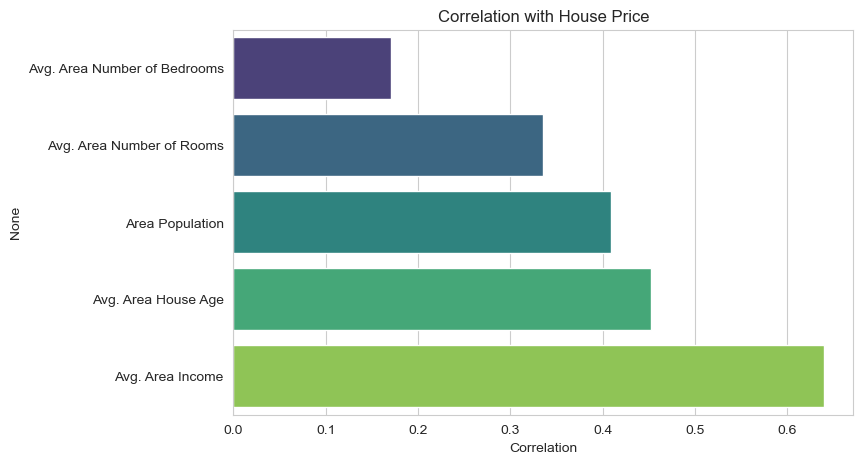

In [45]:
# Feature Impact Comparison:

corr_price = (
    USAhousing.corr(numeric_only=True)['Price']
    .drop('Price')
    .sort_values()
)

plt.figure(figsize=(8,5))

sns.barplot(
    x=corr_price.values,
    y=corr_price.index,
    hue = corr_price.index,
    palette='viridis'
)

plt.title("Correlation with House Price")
plt.xlabel("Correlation")
plt.show()

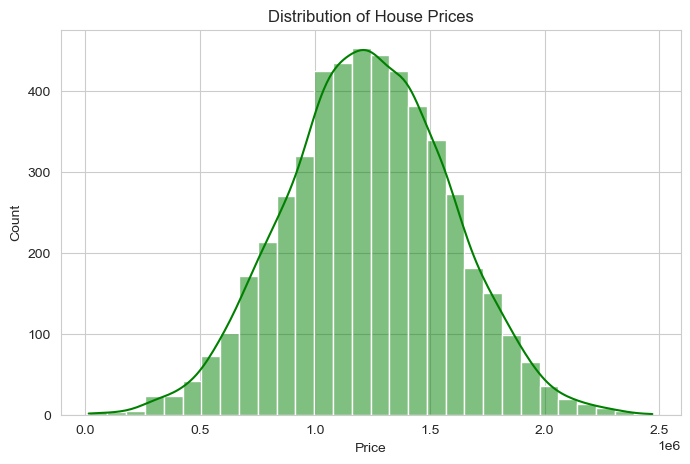

In [46]:
# Target Variable Distribution:

plt.figure(figsize=(8,5))

sns.histplot(
    USAhousing['Price'],
    kde=True,
    bins=30,
    color='green'
)

plt.title("Distribution of House Prices")
plt.show()

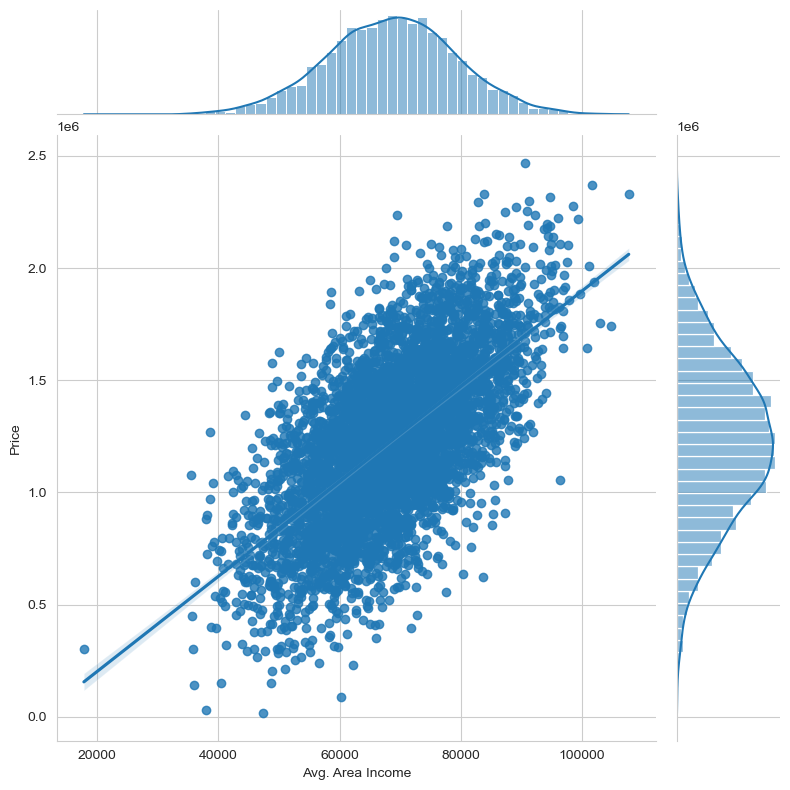

In [47]:
sns.jointplot(
    data=USAhousing,
    x='Avg. Area Income',
    y='Price',
    kind='reg',
    height=8
)

plt.show()

## Specify your X and Y - Independent variables vs dependent variable

In [48]:
USAhousing.columns

Index(['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population', 'Price', 'Address'],
      dtype='object')

In [49]:
X = USAhousing[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms',
       'Avg. Area Number of Bedrooms', 'Area Population']]
y = USAhousing["Price"]

## Train Test Split

In [50]:
from sklearn.model_selection import train_test_split

In [51]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3)

## Creating and Training a Linear Regression Model:

In [ ]:
from sklearn.linear_model import LinearRegression #STEP 1: Import the algorithm module

lr = LinearRegression() #STEP 2: Instantiate: Creating an object of the class

lr.fit(X_train,y_train) #STEP 3: Learn between X_train and y_train --> fit

y_pred = lr.predict(X_test) #STEP 4: Predict on X_test

## Model Evaluation

In [58]:
print(lr.intercept_)

-2625168.81938522


In [59]:
print(lr.coef_)

[2.16688708e+01 1.64844781e+05 1.18583825e+05 2.47276133e+03
 1.51970200e+01]


In [61]:
coef_df = pd.DataFrame(lr.coef_,X.columns,columns = ["Coefficient of X"])
coef_df

,Coefficient of X
Avg. Area Income,21.668871
Avg. Area House Age,164844.780549
Avg. Area Number of Rooms,118583.825132
Avg. Area Number of Bedrooms,2472.761335
Area Population,15.197020


In [69]:
from sklearn import metrics
from sklearn.metrics import r2_score

In [65]:
# Mean absolute Error
print(metrics.mean_absolute_error(y_test,y_pred))

81849.62787036672


In [66]:
# Mean squared Error
print(metrics.mean_squared_error(y_test,y_pred))

10329170002.183603


In [67]:
# Root Mean squared Error
print(np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

101632.524332438


In [74]:
# R-squared
r2 = r2_score(y_test, y_pred)
print(round(r2*100,2),"%")

92.11 %


# Experiment 2: Model with one less variable (Based on correlation analysis)

In [78]:
X = USAhousing[['Avg. Area Income', 'Avg. Area House Age', 'Avg. Area Number of Rooms', 'Area Population']]
y = USAhousing["Price"]

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.3)

from sklearn.linear_model import LinearRegression #STEP 1: Import the algorithm module
lr = LinearRegression() #STEP 2: Instantiate: Creating an object of the class
lr.fit(X_train,y_train) #STEP 3: Learn between X_train and y_train --> fit
y_pred = lr.predict(X_test) #STEP 4: Predict on X_test

# Root Mean squared Error
print("Root Mean Squared Error is:",np.sqrt(metrics.mean_squared_error(y_test,y_pred)))

# R-squared
r2 = r2_score(y_test, y_pred)
print("R squared is:",round(r2*100,2),"%")

Root Mean Squared Error is: 101010.4889437983
R squared is: 92.34 %
